In [1]:
import numpy as np
import h2py
import pickle
import matplotlib.pyplot as plt
import scipy
import pandas
import demes

import matplotlib as mpl
mpl.rc("xtick", labelsize=7)
mpl.rc("ytick", labelsize=7)
mpl.rc("font", size=8)
mpl.rc("axes", labelsize=8)
mpl.rc("axes", titlesize=8)
mpl.rc("legend", fontsize=7)
mpl.rc("axes", titlesize="small")

In [5]:
# Load fitted bootstrap parameters
data = []
for rep in range(500):
    fnames = []
    lls = []
    for trial in range(5):
        fname = f"model_fits/fit_rep{rep}_trial{trial}.yaml"
        fnames.append(fname)
        g = demes.load(fname)
        lls.append(g.metadata["opt_info"]["ll"])
    fname = fnames[np.argmax(lls)]
    pvals, pnames = h2py.inference.load_params(fname, "models/params_full.yaml")
    data.append(pvals)
median = np.median(data, axis=0)
lower_CI = np.quantile(data, 0.025, axis=0) 
upper_CI = np.quantile(data, 0.975, axis=0) 
df = pandas.DataFrame({"name": pnames, "MLE": median, "CI_lower": lower_CI, "CI_upper": upper_CI})
df.to_csv("parametric_bootstrap.csv")

In [3]:
# Load fitted empirical (block) bootstrap parameters
data = []
for rep in range(500):
    fnames = []
    lls = []
    for trial in range(5):
        try:
            fname = f"../../models/bootstrap_models/bherer_full/sample_{rep}_try_{trial}.yaml"
            g = demes.load(fname)
        except:
            continue
        lls.append(g.metadata["opt_info"]["ll"])
        fnames.append(fname)
    fname = fnames[np.argmax(lls)]
    pvals, pnames = h2py.inference.load_params(fname, "models/params_full.yaml")
    data.append(pvals)
mle, _ = h2py.inference.load_params("../../models/main_models/bherer_full.yaml", "models/params_full.yaml")
lower_CI = np.quantile(data, 0.025, axis=0) 
upper_CI = np.quantile(data, 0.975, axis=0) 
df = pandas.DataFrame({"name": pnames, "MLE": mle, "CI_lower": lower_CI, "CI_upper": upper_CI})
df.to_csv("empirical_bootstrap.csv")

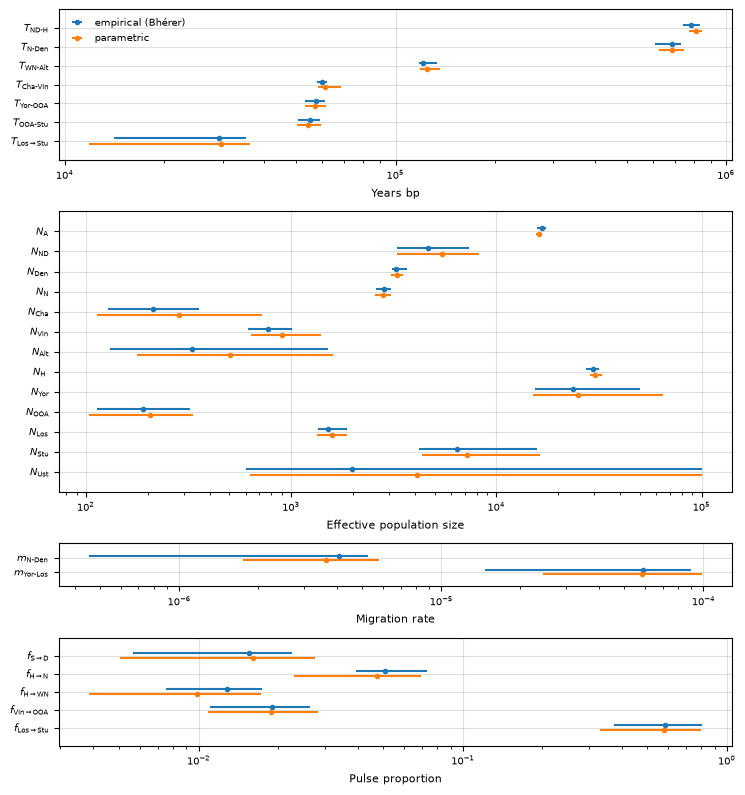

In [2]:
# df0 = pandas.read_csv("empirical_bootstrap.csv")
df0 = pandas.read_csv("../../models/mutation_sensitivity/bootstrap_bherer_1.3e-8.csv")
df1 = pandas.read_csv("parametric_bootstrap.csv")
groups = [
    {"params": ['T_NDH', 'T_ND', 'T_AWN', 'T_CV', 'T_OOA', 'T_SL', 'T_L_S'], "log": True},
    {"params": ['N_Anc', 'N_ND', 'N_Den', 'N_N', 'N_Chag', 'N_Vin', 'N_Alt', 'N_MH', 'N_Yor', 'N_OOA', 'N_Los', 'N_Stut', 'N_Ust'],
     "log": True},
    {"params": ["m_ND", "m_LY"], "log": True},
    {"params": ["p_S_D", "p_H_N", "p_H_WN", "p_N_OOA", "p_L_S"], "log": True}
]

x_labels = ["Years bp", "Effective population size", "Migration rate",  "Pulse proportion"]
param_labels = {
    'T_NDH': r'$T_{\text{ND-H}}$',
    'T_ND': r'$T_{\text{N-Den}}$', 
    'T_AWN': r'$T_{\text{WN-Alt}}$', 
    'T_CV': r'$T_{\text{Cha-Vin}}$', 
    'T_OOA': r'$T_{\text{Yor-OOA}}$', 
    'T_SL': r'$T_{\text{OOA-Stu}}$', 
    'T_L_S': r'$T_{\text{Los}\to\text{Stu}}$', 
    'N_Anc': r'$N_{\text{A}}$',
    "N_S": r"$N_{\text{S}}$ (fixed)",
    'N_ND': r'$N_{\text{ND}}$', 
    'N_N': r'$N_{\text{N}}$', 
    'N_MH': r'$N_{\text{H}}$ ', 
    'N_OOA': r'$N_{\text{OOA}}$',
    'N_Alt': r'$N_{\text{Alt}}$', 
    'N_Chag': r'$N_{\text{Cha}}$', 
    'N_Vin': r'$N_{\text{Vin}}$', 
    'N_Den': r'$N_{\text{Den}}$',
    'N_Los': r'$N_{\text{Los}}$',
    'N_Ust': r'$N_{\text{Ust}}$',
    'N_Stut': r'$N_{\text{Stu}}$',
    'N_Yor': r'$N_{\text{Yor}}$', 
    'm_ND': r'$m_{\text{N-Den}}$', 
    'm_LY': r'$m_{\text{Yor-Los}}$', 
    'p_S_D': r'$f_{\text{S} \to \text{D}}$', 
    'p_H_N': r'$f_{\text{H} \to \text{N}}$',
    'p_H_WN': r'$f_{\text{H} \to \text{WN}}$', 
    'p_N_OOA': r'$f_{\text{Vin}\to\text{OOA}}$', 
    'p_L_S': r'$f_{\text{Los}\to\text{Stu}}$',
}

h2py.plotting.plot_param_distributions(
    [df0, df1],
    groups=groups,
    param_labels=param_labels,
    data_labels=["empirical (Bhérer)", "parametric"],
    figsize=(7.5, 8),
    x_labels=x_labels,
    spread=0.15,
    out="../../figures/parametric_bootstrap.pdf"
)

In [ ]:
graph = "models/bherer_full.yaml"
fname = "simulation_outputs/bherer_full_rep0_boot_h2.pkl"
with open(fname, "rb") as fin:
    data = pickle.load(fin)

In [7]:
model = h2py.H2stats.from_demes(graph, u=1.3e-8, r_bins=data["bins"], sampled_demes=data["pops"])

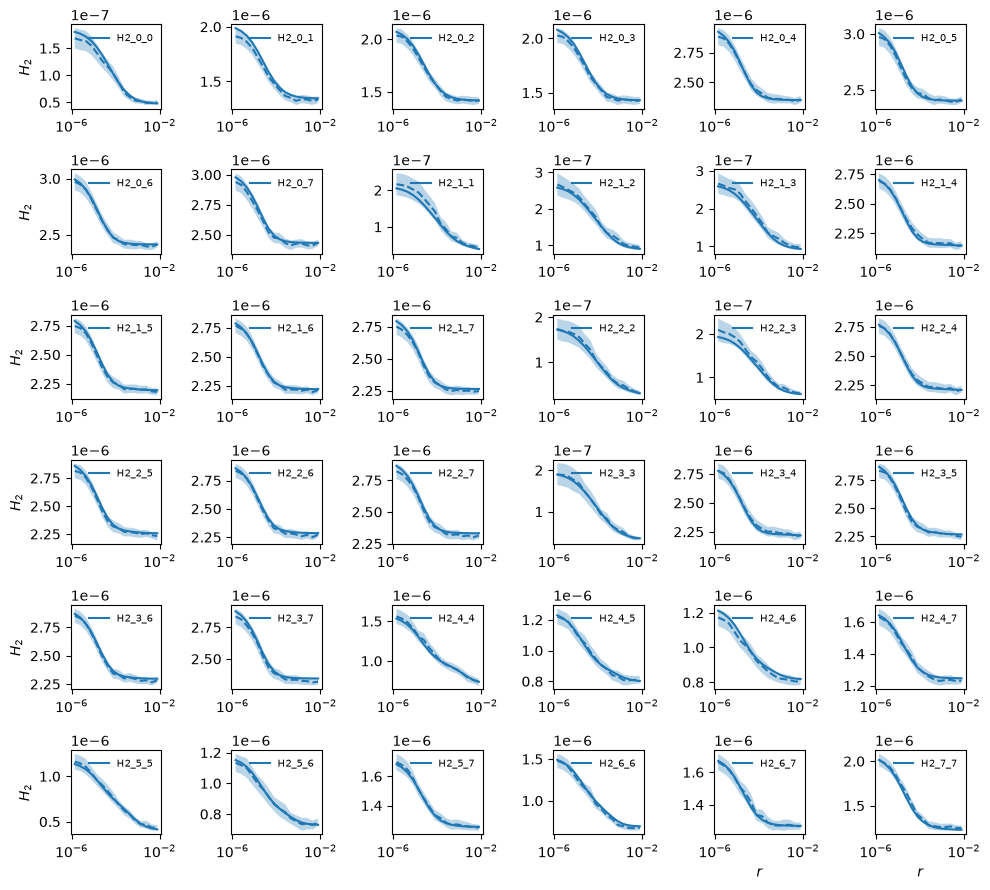

In [8]:
x = h2py.plotting.plot_h2_curves_comp(
    model,
    data["means"],
    data["varcovs"],
    fig_size=(10, 10),
    rows=7,
    r_bins=data["bins"],
)